1. Check the GPU

In [102]:
import torch

print("torch", torch.__version__)
print("cuda", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available. Paste this output before continuing.")
print("device", torch.cuda.get_device_name(0))
print("vram_gb", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))

torch 2.11.0+cu128
cuda True
device NVIDIA GeForce RTX 3060
vram_gb 12.0


2. List the sample images

In [103]:
from pathlib import Path

SAMPLES_DIR = Path(r"C:\Users\amlan\Downloads\Nutrition labels-20261124T102320Z-1-001\Nutrition labels")
images = sorted(
    p for p in SAMPLES_DIR.iterdir()
    if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp", ".tif", ".tiff"}
)
print("count", len(images))
for p in images:
    print(p.name)

count 11
00016000178496_S_s00_CPV101.jpeg
00016000477117_C4N1_s101.jpeg
03415582803166_C4N1_PS 8272009 ACS0725.jpeg
08410076601919_C4N1_700-8802161.jpeg
08410076610355_C4N1_2200907.jpeg
08410076621788_C4N1_2201285.jpeg
08410076801753_C4N1_700-8805387.jpeg
700-8801333_NV Crunchy Oats&Honey 5CT_Carton_2D Cut Out_Nutrition.png
8008-02_Chocolate Swirl Cake Mix_Carton_2D Cut Out_Nutrition (1).jpeg
nutrition-facts-label-food-vector-22455957.jpg
NutritionType1.jpeg


3. Open a label

00016000178496_S_s00_CPV101.jpeg (3000, 3000)


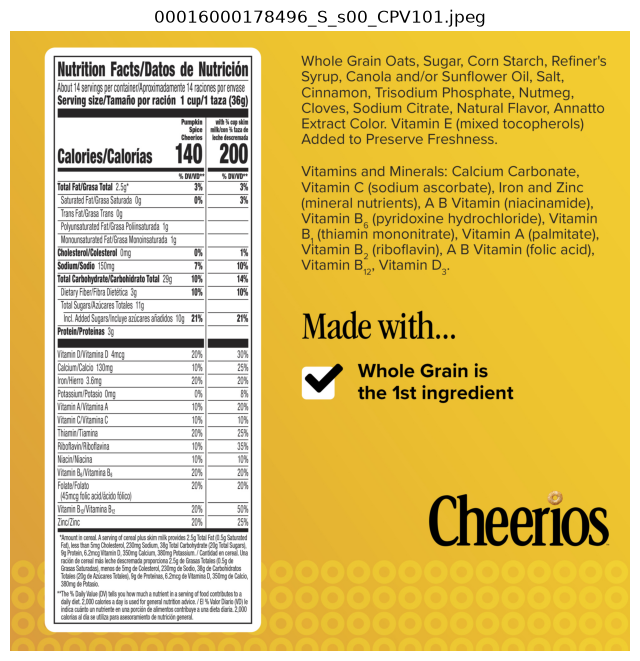

In [104]:
from PIL import Image, PngImagePlugin
import matplotlib.pyplot as plt

# One sample PNG has a compressed text chunk bigger than Pillow's 1 MB cap.
PngImagePlugin.MAX_TEXT_CHUNK = 128 * 1024 * 1024
PngImagePlugin.MAX_TEXT_MEMORY = 512 * 1024 * 1024

def open_label(path):
    with Image.open(path) as im:
        return im.convert("RGB")

SAMPLE_NAME = None  # example: "NutritionType1.jpeg"

path = images[0] if SAMPLE_NAME is None else SAMPLES_DIR / SAMPLE_NAME
img = open_label(path)
print(path.name, img.size)

plt.figure(figsize=(8, 10))
plt.imshow(img)
plt.axis("off")
plt.title(path.name)
plt.show()

4. Crop the nutrition panel from every image

Two cases:

1. The panel is a solid card on a different background, such as the white Cheerios label on yellow. The crop is that card.
2. The photo is already just the table on a plain background. The crop is the content itself, with the empty border removed.

Cropped images are saved under `outputs/panels`. Later OCR should use those files.

card    (3000, 3000) -> (1049, 2831)  00016000178496_S_s00_CPV101.jpeg
content (3000, 3000) -> (1990, 3000)  00016000477117_C4N1_s101.jpeg
content (3000, 3000) -> (2858, 1426)  03415582803166_C4N1_PS 8272009 ACS0725.jpeg
card    (3000, 3000) -> (1551, 2882)  08410076601919_C4N1_700-8802161.jpeg
card    (3000, 3000) -> (2882, 2496)  08410076610355_C4N1_2200907.jpeg
card    (3000, 3000) -> (2262, 2882)  08410076621788_C4N1_2201285.jpeg
card    (3000, 3000) -> (2882, 1047)  08410076801753_C4N1_700-8805387.jpeg
card    (3000, 3000) -> (2486, 2882)  700-8801333_NV Crunchy Oats&Honey 5CT_Carton_2D Cut Out_Nutrition.png
card    (3000, 3000) -> (1868, 2882)  8008-02_Chocolate Swirl Cake Mix_Carton_2D Cut Out_Nutrition (1).jpeg
card    (1000, 1080) -> (486, 760)  nutrition-facts-label-food-vector-22455957.jpg
content (3000, 3000) -> (2882, 1719)  NutritionType1.jpeg


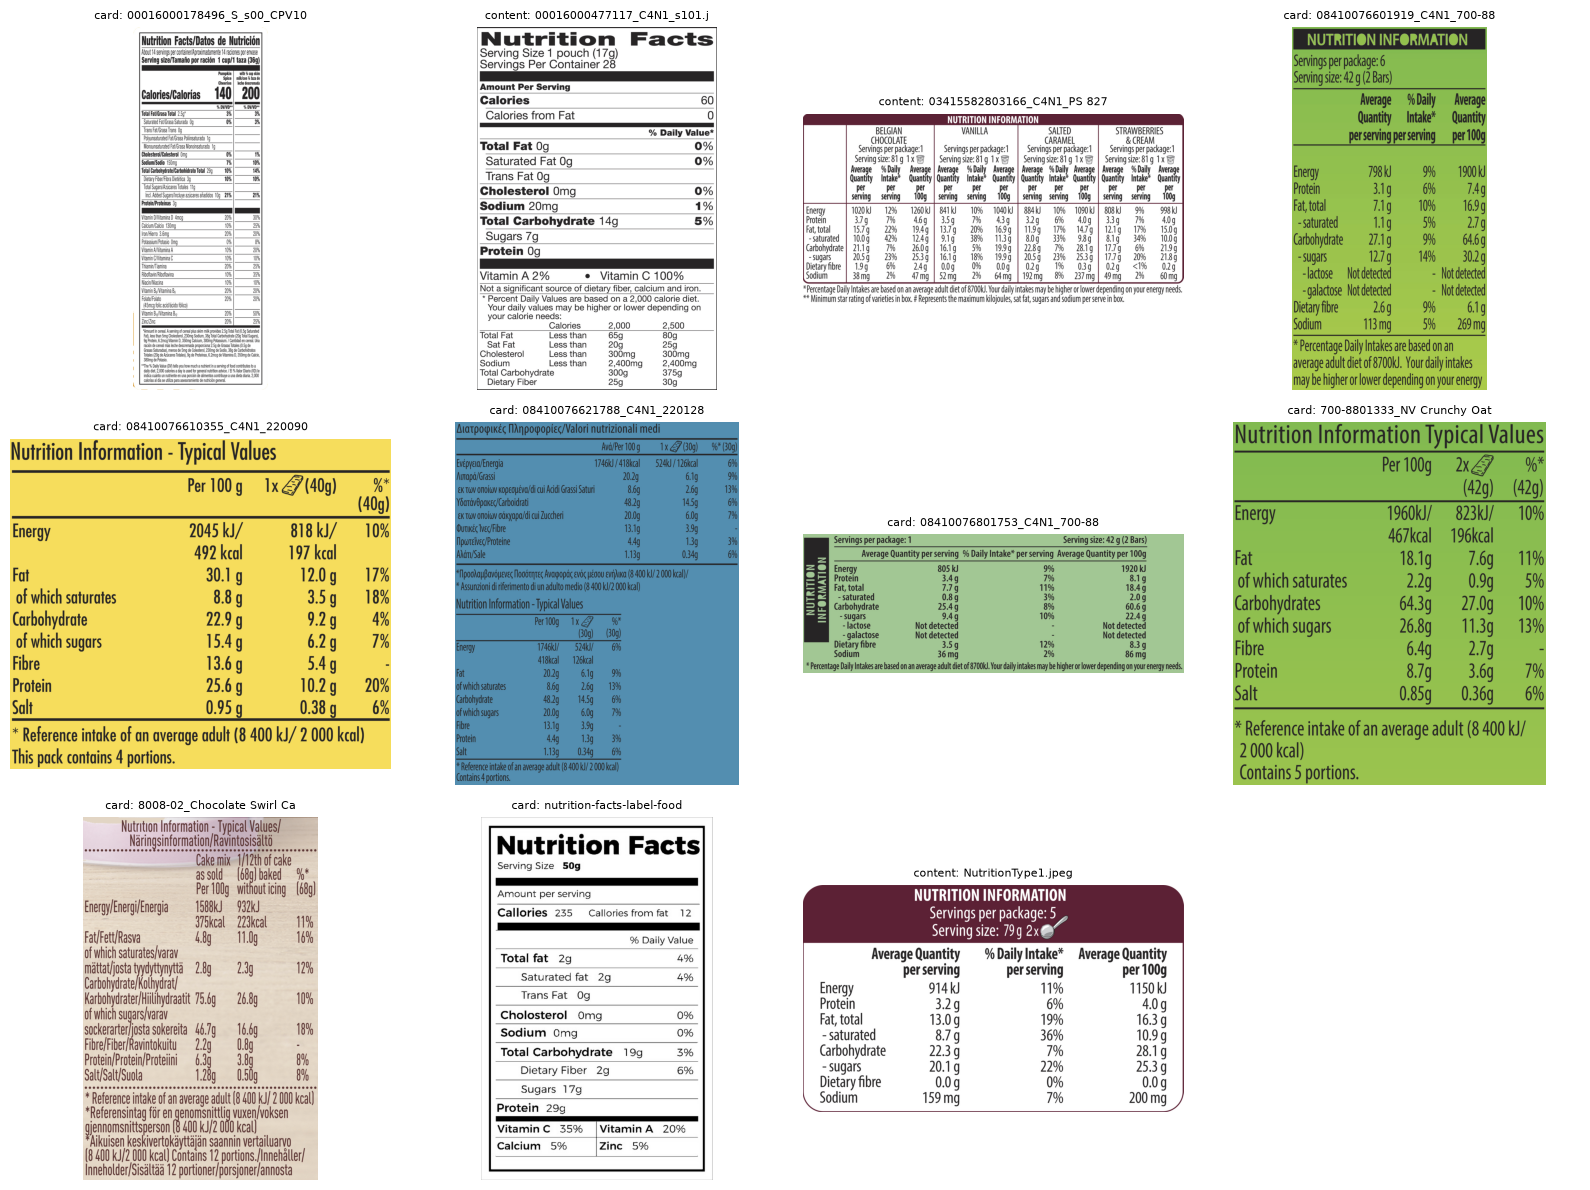

saved 11 crops to C:\Users\amlan\Desktop\testOCR\outputs\panels


In [105]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

PANEL_DIR = Path("outputs") / "panels"
PANEL_DIR.mkdir(parents=True, exist_ok=True)


def _pad(x0, y0, x1, y1, image_w, image_h, pad):
    return (
        max(0, x0 - pad),
        max(0, y0 - pad),
        min(image_w, x1 + pad),
        min(image_h, y1 + pad),
    )


def _solid_bounds(fill, min_fill):
    solid = np.where(fill >= min_fill)[0]
    if len(solid) == 0:
        return 0, len(fill)
    return int(solid[0]), int(solid[-1]) + 1


def _snap_off_background(arr, box, background, tol=26, max_ink=0.015):
    image_h, image_w = arr.shape[:2]
    x0, y0, x1, y1 = box
    step = 2

    def is_background(strip):
        if strip.size == 0:
            return False
        distance = np.linalg.norm(strip.astype(np.int16) - background.astype(np.int16), axis=2)
        return (distance > tol).mean() < max_ink

    while x1 - x0 > 40 and is_background(arr[y0:y1, x0:x0 + step]):
        x0 += step
    while x1 - x0 > 40 and is_background(arr[y0:y1, x1 - step:x1]):
        x1 -= step
    while y1 - y0 > 40 and is_background(arr[y0:y0 + step, x0:x1]):
        y0 += step
    while y1 - y0 > 40 and is_background(arr[y1 - step:y1, x0:x1]):
        y1 -= step
    return max(0, x0), max(0, y0), min(image_w, x1), min(image_h, y1)


def crop_nutrition_panel(image):
    """Return kind, box, and a crop with the photo background removed."""
    arr = np.asarray(image)
    image_h, image_w = arr.shape[:2]
    border_px = max(8, int(min(image_h, image_w) * 0.004))
    border = np.concatenate([
        arr[:border_px].reshape(-1, 3),
        arr[-border_px:].reshape(-1, 3),
        arr[:, :border_px].reshape(-1, 3),
        arr[:, -border_px:].reshape(-1, 3),
    ])
    background = np.median(border, axis=0)
    distance = np.linalg.norm(arr.astype(np.int16) - background.astype(np.int16), axis=2)
    mask = distance > 32
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), 8)
    candidates = []
    for i in range(1, count):
        x, y, bw, bh, area = [int(v) for v in stats[i]]
        if area < 0.04 * image_h * image_w:
            continue
        fill = area / max(1, bw * bh)
        if fill < 0.45:
            continue
        tall = bh >= 0.28 * image_h and bw >= 0.12 * image_w
        wide = bw >= 0.40 * image_w and bh >= 0.15 * image_h
        if not (tall or wide):
            continue
        if bw * bh > 0.96 * image_h * image_w:
            continue
        candidates.append((area, i))
    if not candidates:
        ys, xs = np.where(mask)
        if len(xs) == 0:
            return "full", (0, 0, image_w, image_h), image
        x0, y0, x1, y1 = int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1
        box = _snap_off_background(arr, _pad(x0, y0, x1, y1, image_w, image_h, 8), background)
        x0, y0, x1, y1 = box
        return "content", box, Image.fromarray(arr[y0:y1, x0:x1])

    _, label = max(candidates)
    comp = labels == label
    ys, xs = np.where(comp)
    y0, y1 = int(ys.min()), int(ys.max()) + 1
    x0, x1 = int(xs.min()), int(xs.max()) + 1
    sub = comp[y0:y1, x0:x1]
    ry0, ry1 = _solid_bounds(sub.mean(axis=1), 0.55)
    cx0, cx1 = _solid_bounds(sub.mean(axis=0), 0.55)
    box = _snap_off_background(
        arr,
        _pad(x0 + cx0, y0 + ry0, x0 + cx1, y0 + ry1, image_w, image_h, 2),
        background,
    )
    x0, y0, x1, y1 = box
    cleaned = arr[y0:y1, x0:x1].copy()
    panel = comp[y0:y1, x0:x1]
    if panel.any() and (~panel).any():
        cleaned[~panel] = np.median(cleaned[panel].reshape(-1, 3), axis=0)
    return "card", box, Image.fromarray(cleaned)


panel_crops = []
for path in images:
    label = open_label(path)
    kind, box, crop = crop_nutrition_panel(label)
    dest = PANEL_DIR / f"{path.stem}.png"
    crop.save(dest)
    panel_crops.append((path.name, kind, box, crop))
    print(f"{kind:7} {label.size} -> {crop.size}  {path.name}")

cols = 4
rows = (len(panel_crops) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = list(np.atleast_1d(axes).ravel())
for ax, (name, kind, box, crop) in zip(axes, panel_crops):
    ax.imshow(crop)
    ax.set_title(f"{kind}: {name[:26]}", fontsize=8)
    ax.axis("off")
for ax in axes[len(panel_crops):]:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("saved", len(panel_crops), "crops to", PANEL_DIR.resolve())


5. Mark column headers and row labels on every cropped panel

Green boxes are column headers. Blue boxes are the nutrient names down the left. Serving size and servings per package are not marked. When two nutrition tables are stacked, only the English table is marked.


00016000178496_S_s00_CPV101.png
tables found: 1
column headers
  1. %1 DVVD**
  2. milk/con %t tazac de %1 DVND**
row labels
  Pumpkin with
  Spice milk/con
  Calories/Calorias
  Total Fat/Grasa Total
  Saturated Fat/Grasa Saturada
  Trans Fat/Grasa Trans
  Polyunsaturated Fat/Grasa Polinsaturada
  Monounsaturated Fat/Grasa Monoinsaturada
  Cholesterol/Colesterol
  Sodium/Sodio
  Total CarbohypdratelCarbohidrato Total
  Dietary Fiber/Fibra Dietética
  Total: Sugars/Azucares Totales
  Incl Added Sugars/In Incluye azucares aradidos
  Protein/Proteinas
  Vitamin D/Vitaminal D
  Calcium/Calcio
  Iron/Hierro
  Potassium/Potasio
  Vitamin A/V Vitaminal A
  Vitamin C/Vitamina0 C
  Thiamin/Tiamina
  Riboflavin/ /Riboflavina
  Niacin/Niacina
  Vitamin Bol Vitaminal B6
  Folate/Folato
  Vitamin Bil NVitaminal Bz2
  Zinc/Zinc


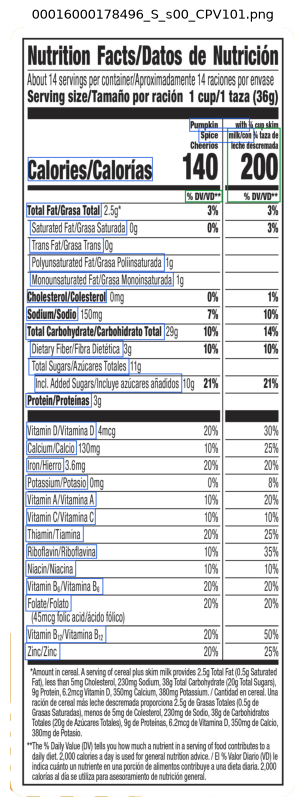


00016000477117_C4N1_s101.png
tables found: 1
column headers
  1. Amount Per Serving
  2. % Daily Value*
row labels
  Calories
  Total Fat
  Saturated Fat
  Trans Fat
  Cholesterol
  Sodium
  Total Carbohydrate
  Sugars
  Protein
  Vitamin A


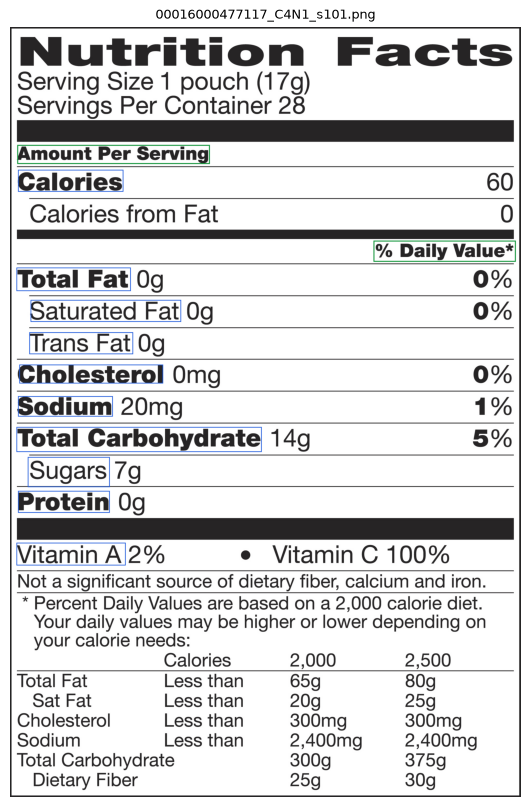


03415582803166_C4N1_PS 8272009 ACS0725.png
tables found: 1
column headers
  1. Average Quantity per serving
  2. % Daily Intake* per serving
  3. Average Quantity per 100g
  4. Average Quantity per serving
  5. %D Daily Intake* per serving
  6. Average Quantity per 100g
  7. Average Quantity per serving
  8. %Daily Intake* per serving
  9. Average Quantity per 100g
  10. Average Quantity per serving
  11. Daily %1 Intake* per serving
  12. Average Quantity per 100g
row labels
  Energy
  Protein
  Fat, total
  saturated
  Carbohydrate
  sugars
  Dietary fibre
  Sodium


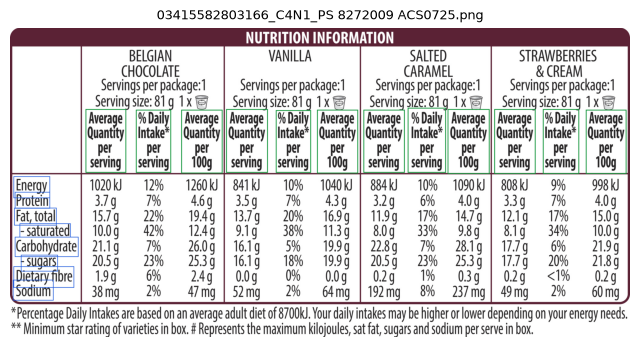


08410076601919_C4N1_700-8802161.png
tables found: 1
column headers
  1. Average Quantity perserving
  2. Intake* perserving
  3. Average Quantity per100g
row labels
  Energy
  Protein
  Fat, total
  saturated
  Carbohydrate
  sugars
  lactose
  galactose
  Dietaryf fibre
  Sodium


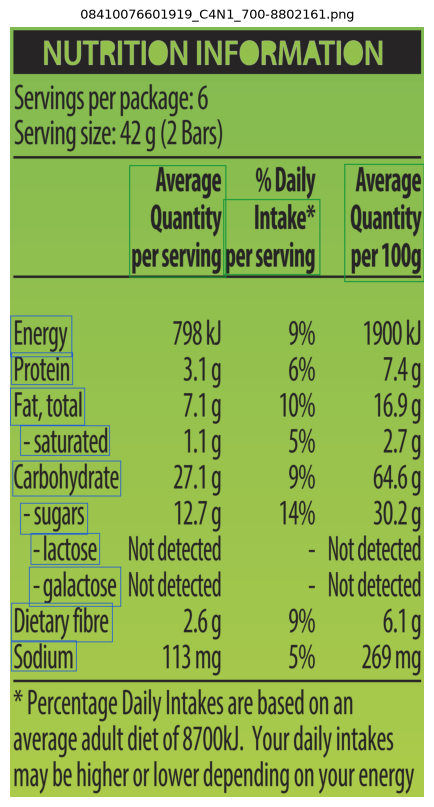


08410076610355_C4N1_2200907.png
tables found: 1
column headers
  1. Per 100 g
  2. 1x 5 (40g)
  3. % (40g)
row labels
  Energy
  Fat
  of which . saturates
  Carbohydrate
  of which - sugars
  Fibre
  Protein
  Salt


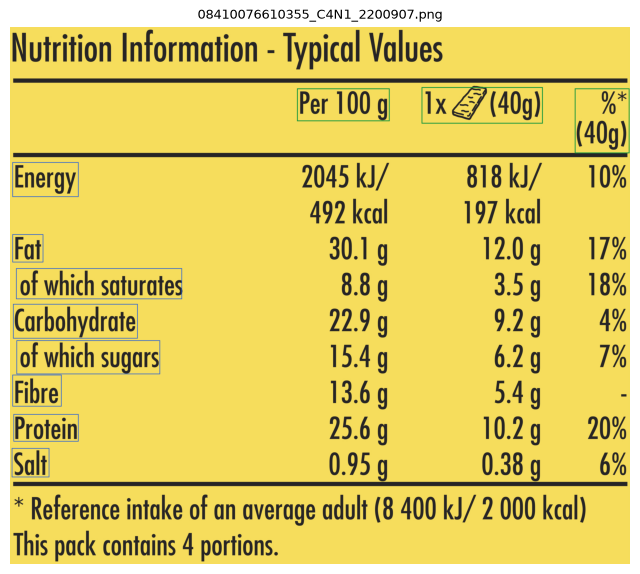


08410076621788_C4N1_2201285.png
tables found: 2. Using the English table only: Nutrition Information = TypicalValues
column headers
  1. Per 100g
  2. 1x E (30g)
  3. % (30g)
row labels
  Energy
  Fat
  ofwhich saturates
  Carbohydrate
  ofwhich sugars
  Fibre
  Protein
  Salt


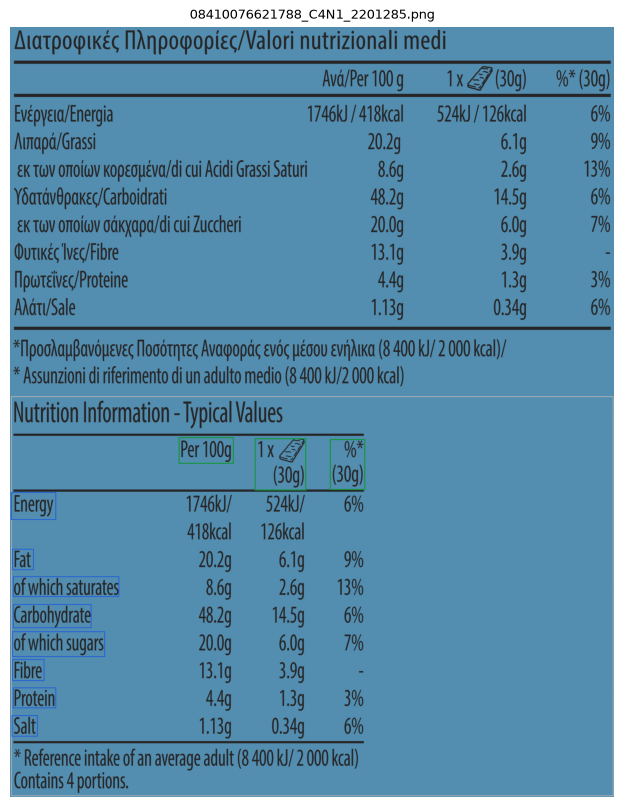


08410076801753_C4N1_700-8805387.png
tables found: 1
column headers
  1. Quantity Average % Daily Intake* serving per
  2. serving Average per
  3. 100g Quantity per
row labels
  Energy
  Protein
  Fat, total
  saturated
  Carbohydrate
  sugars
  lactose
  Dietary fibre
  Sodium


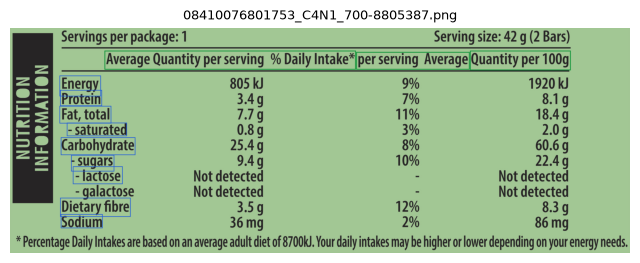


700-8801333_NV Crunchy Oats&Honey 5CT_Carton_2D Cut Out_Nutrition.png
tables found: 1
column headers
  1. Per 100g
  2. 2x (42g)
  3. % X (42g)
row labels
  Energy
  Fat
  ofwhich saturates
  Carbohydrates
  ofwhich sugars
  Fibre
  Protein
  Salt


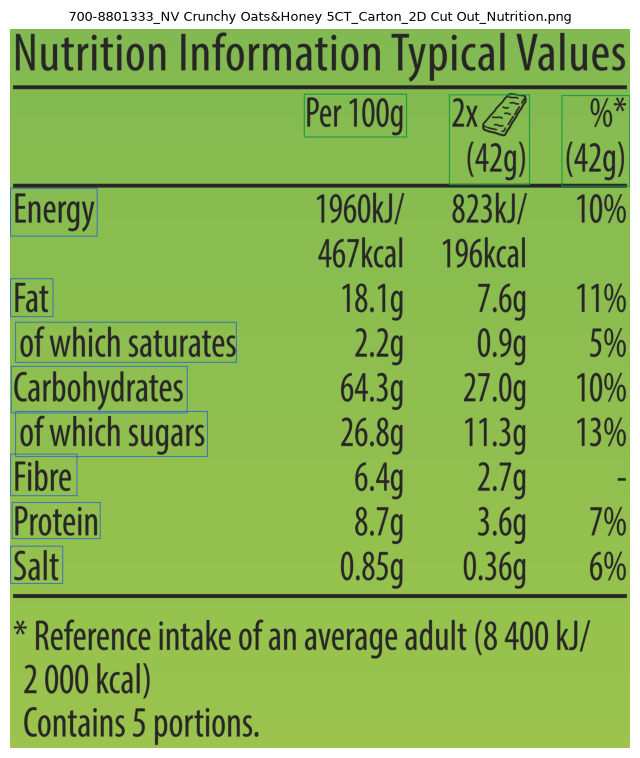


8008-02_Chocolate Swirl Cake Mix_Carton_2D Cut Out_Nutrition (1).png
tables found: 1
column headers
  1. Per 100g 375kcal
  2. (68g) baked 223kcal
  3. 168g] 11%
row labels
  as sold (68g) baked
  Energy/Energi/Energia
  Fat/Fett/Rasva
  maâttat/josta tyydyttynytta
  Karbohydrater/Hiitydraatit
  sockerarter/josta sokereita
  Fibre/Fiber/Ravintokuitu
  Protein/Protein/Protelint
  Salt/Salt/Suola


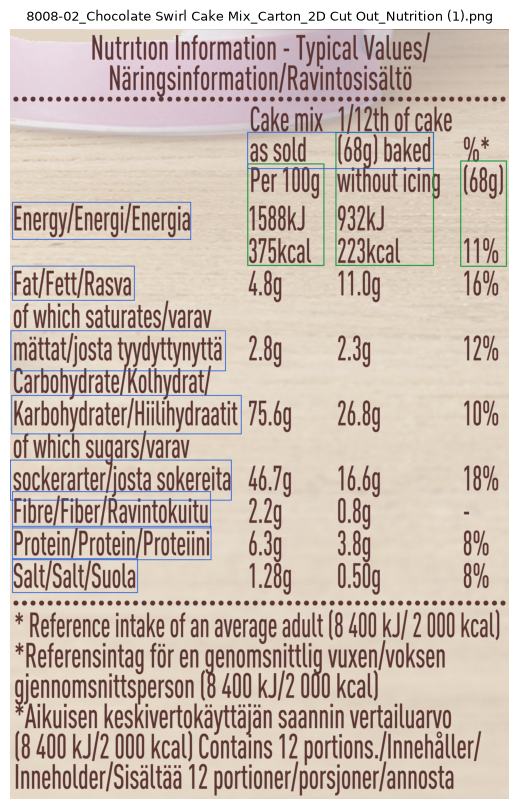


nutrition-facts-label-food-vector-22455957.png
tables found: 1
column headers
  1. Amount per serving
  2. % Daily Value
row labels
  Callories
  Total fat
  Saturated fat
  Trans Fat
  Cholosterol
  Sodium
  Total Carbohydrate
  Dietary Fiber
  Sugars
  Protein
  Vitamin C
  Calcium


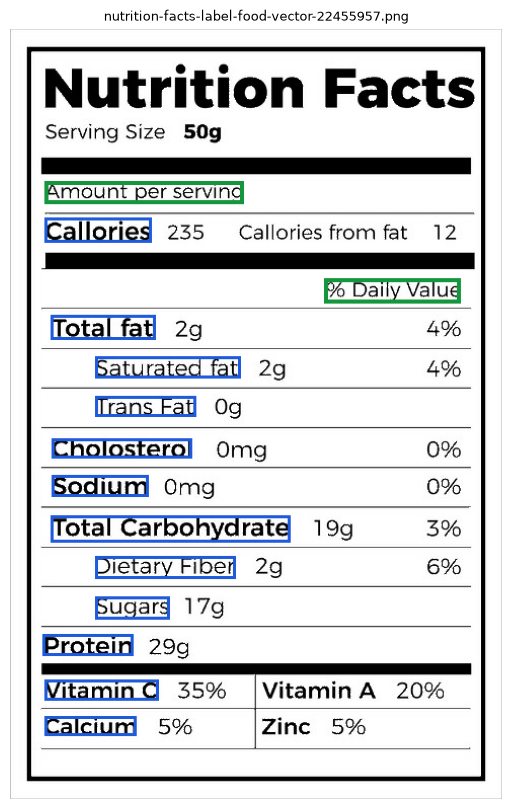


NutritionType1.png
tables found: 1
column headers
  1. Average Quantity per serving
  2. % Daily Intake * per serving
  3. Average Quantity per 100g
row labels
  Energy
  Protein
  Fat, total
  S saturated
  Carbohydrate
  sugars
  Dietary fibre
  Sodium


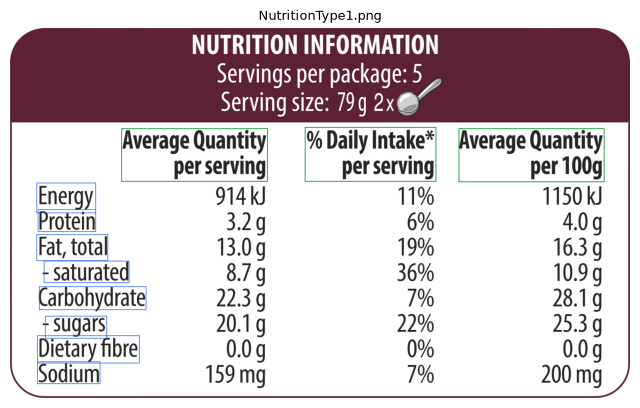

In [106]:
import os
import re
from pathlib import Path

os.environ.setdefault("DOCTR_CACHE_DIR", str(Path(r"c:\Users\amlan\Desktop\testOCR\.cache\doctr")))

import numpy as np
from PIL import Image, ImageDraw
from doctr.models import ocr_predictor

VALUE_RE = re.compile(
    r"^(?:notdetected|[-–]|o?g|o?mg|\d+(?:[.,]\d+)?(?:kJ|kcal|mcg|mg|g|%)?)$",
    re.I,
)
NUTRIENT_WORDS = (
    "calorie", "energy", "fat", "protein", "carb", "sodium", "salt",
    "fibre", "fiber", "sugar", "vitamin", "calcium", "iron", "cholesterol",
)
COLUMN_HINTS = (
    "per", "daily", "quantity", "average", "amount", "intake", "dv",
    "value", "%", "100", "serving",
)


def is_value(text):
    token = text.strip().strip("*/\\").replace(" ", "")
    if re.fullmatch(r"k(?:cal|j)", token, re.I):
        return True
    return "%" in token or bool(VALUE_RE.match(token))


def row_text(row):
    return " ".join(word["text"] for word in row["words"])


def is_nutrient_row(row):
    text = row_text(row).lower()
    return any(key in text for key in NUTRIENT_WORDS) and any(is_value(word["text"]) for word in row["words"])


def line_role(text):
    lowered = text.lower()
    if re.search(r"servings?\s+per\s+(package|container|pack|carton|box)", lowered):
        return "servings_per_package"
    if re.search(r"serving\s+size", lowered):
        return "serving_size"
    if re.search(r"contains\s+\d+\s+portions?", lowered):
        return "servings_per_package"
    if re.match(r"nutrition\b", lowered) and not any(hint in lowered for hint in ("per", "quantity", "daily", "amount")):
        return "title"
    return None


def is_column_header_text(text):
    lowered = text.lower()
    if any(hint in lowered for hint in COLUMN_HINTS):
        return True
    return bool(re.search(r"\d+\s*(?:g|mg)\b", lowered))


def words_from_page(page):
    height, width = page.dimensions
    words = []
    for block in page.blocks:
        for line in block.lines:
            for word in line.words:
                (x0, y0), (x1, y1) = word.geometry
                words.append({
                    "text": word.value,
                    "x0": x0 * width,
                    "y0": y0 * height,
                    "x1": x1 * width,
                    "y1": y1 * height,
                })
    words.sort(key=lambda item: ((item["y0"] + item["y1"]) / 2, item["x0"]))
    return words, width


def group_rows(words):
    rows = []
    for word in words:
        placed = False
        if rows:
            row = rows[-1]
            overlap = min(word["y1"], row["y1"]) - max(word["y0"], row["y0"])
            word_height = max(1.0, min(word["y1"] - word["y0"], row["y1"] - row["y0"]))
            if overlap > 0.4 * word_height:
                row["words"].append(word)
                row["y0"] = min(row["y0"], word["y0"])
                row["y1"] = max(row["y1"], word["y1"])
                placed = True
        if not placed:
            rows.append({"y0": word["y0"], "y1": word["y1"], "words": [word]})
    for row in rows:
        row["words"].sort(key=lambda item: item["x0"])
        row["text"] = row_text(row)
        row["role"] = line_role(row["text"])
    return rows


def chunks_of(row, width):
    gap = max(22.0, width * 0.018)
    chunks = []
    for word in row["words"]:
        if chunks and word["x0"] - chunks[-1]["x1"] <= gap:
            chunk = chunks[-1]
            chunk["words"].append(word)
            chunk["x1"] = max(chunk["x1"], word["x1"])
            chunk["y0"] = min(chunk["y0"], word["y0"])
            chunk["y1"] = max(chunk["y1"], word["y1"])
        else:
            chunks.append({
                "words": [word],
                "x0": word["x0"],
                "x1": word["x1"],
                "y0": word["y0"],
                "y1": word["y1"],
            })
    for chunk in chunks:
        chunk["text"] = " ".join(word["text"] for word in chunk["words"])
    return chunks


def columns_overlapped(chunk, columns):
    hits = []
    for index, column in enumerate(columns):
        overlap = min(chunk["x1"], column["x1"]) - max(chunk["x0"], column["x0"])
        if overlap <= 0:
            continue
        column_width = max(1.0, column["x1"] - column["x0"])
        chunk_width = max(1.0, chunk["x1"] - chunk["x0"])
        if overlap / column_width >= 0.35 or overlap / chunk_width >= 0.5:
            hits.append(index)
    return hits


def extract_headers(page):
    words, width = words_from_page(page)
    rows = group_rows(words)
    nutrient_indexes = [i for i, row in enumerate(rows) if is_nutrient_row(row)]
    if not nutrient_indexes:
        window_end = min(len(rows), 8)
    elif len(nutrient_indexes) == 1:
        window_end = min(len(rows), nutrient_indexes[0] + 3)
    else:
        window_end = nutrient_indexes[1]

    window = []
    for index, row in enumerate(rows[:window_end]):
        if row["role"] in {"title", "serving_size", "servings_per_package"}:
            continue
        if is_nutrient_row(row):
            continue
        row["chunks"] = chunks_of(row, width)
        if row["chunks"]:
            window.append(row)

    if not window:
        return {"rows": rows, "serving": [], "sections": [], "columns": []}

    base = max(window, key=lambda row: (len(row["chunks"]), row["y0"]))
    columns = []
    for chunk in base["chunks"]:
        columns.append({
            "x0": chunk["x0"],
            "x1": chunk["x1"],
            "y0": chunk["y0"],
            "y1": chunk["y1"],
            "parts": [chunk],
            "sections": [],
        })

    extras = []
    for row in window:
        if row is base:
            continue
        for chunk in row["chunks"]:
            joined = re.sub(r"[^a-z0-9]", "", chunk["text"].lower())
            header_unit = joined in {"100g", "100"} or bool(re.fullmatch(r"\d{2,3}g", joined) and joined.startswith("100"))
            if all(is_value(word["text"]) for word in chunk["words"]) and not header_unit:
                continue
            if header_unit:
                center = (chunk["x0"] + chunk["x1"]) / 2
                nearest = min(range(len(columns)), key=lambda i: abs(((columns[i]["x0"] + columns[i]["x1"]) / 2) - center))
                columns[nearest]["parts"].append(chunk)
                columns[nearest]["x0"] = min(columns[nearest]["x0"], chunk["x0"])
                columns[nearest]["x1"] = max(columns[nearest]["x1"], chunk["x1"])
                columns[nearest]["y1"] = max(columns[nearest]["y1"], chunk["y1"])
                continue
            hits = columns_overlapped(chunk, columns)
            if not hits and is_column_header_text(chunk["text"]):
                extras.append(chunk)
                continue
            if len(hits) >= 2 and is_column_header_text(chunk["text"]):
                for word in chunk["words"]:
                    center = (word["x0"] + word["x1"]) / 2
                    nearest = min(
                        range(len(columns)),
                        key=lambda i: abs(((columns[i]["x0"] + columns[i]["x1"]) / 2) - center),
                    )
                    columns[nearest]["parts"].append({
                        "text": word["text"],
                        "x0": word["x0"],
                        "x1": word["x1"],
                        "y0": word["y0"],
                        "y1": word["y1"],
                    })
                continue
            if not hits:
                continue
            if len(hits) >= 2 or not is_column_header_text(chunk["text"]):
                for hit in hits:
                    columns[hit]["sections"].append(chunk)
            else:
                columns[hits[0]]["parts"].append(chunk)
    for chunk in extras:
        columns.append({
            "x0": chunk["x0"],
            "x1": chunk["x1"],
            "y0": chunk["y0"],
            "y1": chunk["y1"],
            "parts": [chunk],
            "sections": [],
        })
    columns.sort(key=lambda column: column["x0"])

    def phrase(chunks):
        ordered = sorted(chunks, key=lambda item: (item["y0"], item["x0"]))
        return " ".join(item["text"] for item in ordered)

    first_nutrient = nutrient_indexes[0] if nutrient_indexes else len(rows)
    serving = [
        {
            "role": row["role"],
            "text": row["text"],
            "box": (
                min(word["x0"] for word in row["words"]),
                row["y0"],
                max(word["x1"] for word in row["words"]),
                row["y1"],
            ),
        }
        for index, row in enumerate(rows[:first_nutrient])
        if row["role"] in {"serving_size", "servings_per_package"}
    ]
    named = []
    for column in columns:
        named.append({
            "header": phrase(column["parts"]),
            "sections": phrase(column["sections"]),
            "box": (
                min(part["x0"] for part in column["parts"]),
                min(part["y0"] for part in column["parts"] + column["sections"]),
                max(part["x1"] for part in column["parts"]),
                max(part["y1"] for part in column["parts"] + column["sections"]),
            ),
            "header_box": (
                min(part["x0"] for part in column["parts"]),
                min(part["y0"] for part in column["parts"]),
                max(part["x1"] for part in column["parts"]),
                max(part["y1"] for part in column["parts"]),
            ),
            "section_boxes": [(chunk["x0"], chunk["y0"], chunk["x1"], chunk["y1"], chunk["text"]) for chunk in column["sections"]],
        })
    return {"rows": rows, "serving": serving, "columns": named}


def draw_headers(image, result):
    canvas = image.convert("RGB").copy()
    draw = ImageDraw.Draw(canvas)
    for item in result["serving"]:
        draw.rectangle(item["box"], outline=(30, 90, 220), width=4)
    for column in result["columns"]:
        draw.rectangle(column["header_box"], outline=(20, 150, 60), width=4)
        for box in column["section_boxes"]:
            draw.rectangle(box[:4], outline=(230, 120, 20), width=4)
    return canvas




HEADER_TOKENS = {
    "per", "daily", "quantity", "average", "amount", "intake", "dv", "value",
    "values", "typical", "serving", "size", "the", "of", "which", "a", "an",
}


def is_serving_line(text):
    lowered = text.lower()
    if re.search(r"serving\s+size", lowered):
        return True
    if re.search(r"servings?\s+per\s+(package|container|pack|carton|box)", lowered):
        return True
    return False


def is_header_phrase(text):
    tokens = re.findall(r"[a-z%]+", text.lower())
    if not tokens:
        return True
    return all(token in HEADER_TOKENS or token in {"100", "g", "mg"} for token in tokens)


def _cell_words(words):
    cells = []
    for word in words:
        token = word["text"].strip()
        if token in {"-", "\u2013"}:
            continue
        compact = token.lower().replace(" ", "")
        if is_value(token) or "notdetected" in compact:
            cells.append(word)
    return cells


def row_labels_from(rows, columns):
    """Nutrient names down the left, including indented lines and rows above a late % DV header."""
    labels = []
    for row in rows:
        text = row["text"]
        if is_serving_line(text) or text.lower().strip().startswith("nutrition"):
            continue
        if text.strip().startswith("*"):
            break
        cells = _cell_words(row["words"])
        has_not_detected = "notdetected" in text.lower().replace(" ", "")
        if not cells and not has_not_detected:
            continue
        if cells:
            first_value_x = min(word["x0"] for word in cells)
        else:
            first_value_x = min(column["header_box"][0] for column in columns) if columns else 10**9
        names = [
            word for word in row["words"]
            if word not in cells and (word["x0"] + word["x1"]) / 2 < first_value_x + 8
        ]
        if not names:
            continue
        label = " ".join(word["text"] for word in names).strip(" -")
        if not label or is_header_phrase(label):
            continue
        labels.append({
            "text": label,
            "box": (
                min(word["x0"] for word in names),
                min(word["y0"] for word in names),
                max(word["x1"] for word in names),
                max(word["y1"] for word in names),
            ),
        })
    return labels


def split_wide_header(columns, rows, width):
    """Split one header bar into the columns the numbers actually form."""
    if len(columns) != 1:
        return columns
    centers = []
    for row in rows:
        if is_serving_line(row["text"]) or row["text"].strip().startswith("*"):
            continue
        for word in _cell_words(row["words"]):
            centers.append((word["x0"] + word["x1"]) / 2)
    centers.sort()
    gap = max(50.0, width * 0.08)
    slots = []
    for center in centers:
        if not slots or center - slots[-1] > gap:
            slots.append(center)
        else:
            slots[-1] = (slots[-1] + center) / 2
    if len(slots) < 2:
        return columns
    box = columns[0]["header_box"]
    words = []
    for row in rows:
        if is_serving_line(row["text"]) or row["text"].strip().startswith("*"):
            continue
        for word in row["words"]:
            center_y = (word["y0"] + word["y1"]) / 2
            center_x = (word["x0"] + word["x1"]) / 2
            if box[1] - 8 <= center_y <= box[3] + 8 and box[0] - 8 <= center_x <= box[2] + 8:
                words.append(word)
    grouped = {index: [] for index in range(len(slots))}
    for word in words:
        center = (word["x0"] + word["x1"]) / 2
        nearest = min(range(len(slots)), key=lambda index: abs(slots[index] - center))
        grouped[nearest].append(word)
    split = []
    for index in range(len(slots)):
        chosen = sorted(grouped[index], key=lambda word: (word["y0"], word["x0"]))
        if not chosen:
            continue
        split.append({
            "header": " ".join(word["text"] for word in chosen),
            "header_box": (
                min(word["x0"] for word in chosen),
                min(word["y0"] for word in chosen),
                max(word["x1"] for word in chosen),
                max(word["y1"] for word in chosen),
            ),
            "parts": [{"words": chosen, "x0": 0, "x1": 0, "y0": 0, "y1": 0, "text": ""}],
            "sections": "",
        })
    return split or columns
import matplotlib.pyplot as plt

if "predictor" not in globals():
    predictor = ocr_predictor(
        det_arch="db_resnet50",
        reco_arch="crnn_vgg16_bn",
        pretrained=True,
        assume_straight_pages=True,
    ).cuda()
    predictor.eval()

def english_table_start(rows, image_height):
    """Return the top of the English nutrition table when another table is stacked above it."""
    for row in rows:
        lowered = row["text"].lower()
        if "nutrition information" in lowered or "nutrition facts" in lowered:
            if row["y0"] > image_height * 0.2:
                return row
            return None
    return None


panel_dir = Path("outputs") / "panels"
for crop_path in sorted(panel_dir.glob("*.png")):
    image = Image.open(crop_path).convert("RGB")
    page = predictor([np.asarray(image)]).pages[0]
    preview = extract_headers(page)
    english_row = english_table_start(preview["rows"], image.height)
    y_offset = 0
    table_count = 1
    work = image
    if english_row is not None:
        table_count = 2
        y_offset = max(0, int(english_row["y0"]) - 8)
        work = image.crop((0, y_offset, image.width, image.height))
        page = predictor([np.asarray(work)]).pages[0]
    found = preview if english_row is None else extract_headers(page)
    columns = [
        column for column in found["columns"]
        if column["header"].strip() and not is_serving_line(column["header"])
    ]
    columns = split_wide_header(columns, found["rows"], work.width if english_row is not None else image.width)
    labels = row_labels_from(found["rows"], columns)

    print("\n" + crop_path.name)
    if table_count == 2:
        print("tables found: 2. Using the English table only:", english_row["text"])
    else:
        print("tables found: 1")
    print("column headers")
    for index, column in enumerate(columns, start=1):
        print(f"  {index}. {column['header']}")
    print("row labels")
    for label in labels:
        print(f"  {label['text']}")

    canvas = image.copy()
    pen = ImageDraw.Draw(canvas)
    if table_count == 2:
        pen.rectangle((4, y_offset, image.width - 4, image.height - 4), outline=(180, 180, 180), width=3)
    for column in columns:
        box = column["header_box"]
        pen.rectangle((box[0], box[1] + y_offset, box[2], box[3] + y_offset), outline=(20, 150, 60), width=4)
    for label in labels:
        box = label["box"]
        pen.rectangle((box[0], box[1] + y_offset, box[2], box[3] + y_offset), outline=(30, 90, 220), width=3)

    plt.figure(figsize=(8, 10))
    plt.imshow(canvas)
    plt.title(crop_path.name, fontsize=9)
    plt.axis("off")
    plt.show()


6. Map the table into the nutrition JSON

Each value column becomes one panel, the same shape as `sample.json`. `servingSize` and `servingsPer` are copied onto every panel. A row name such as Energy, Fat, or Sodium chooses the field, and the unit chooses Grams, Milligrams, Kilojoules, or Percent.

Change `CROP_NAME` to try another file in `outputs/panels`.

In [108]:
import json
import re
from copy import deepcopy
from pathlib import Path

CROP_NAME = "nutrition-facts-label-food-vector-22455957.png"

ALIASES = [
    ("addedSugar", ["added sugar", "added sugars"]),
    ("saturatedFat", ["saturate"]),
    ("transFat", ["trans fat", "trans"]),
    ("polyunsaturatedFat", ["polyunsaturated"]),
    ("monounsaturatedFat", ["monounsaturated"]),
    ("dietaryFiber", ["fibre", "fiber"]),
    ("totalFat", ["fat"]),
    ("sugar", ["sugar"]),
    ("protein", ["protein"]),
    ("sodium", ["sodium"]),
    ("salt", ["salt"]),
    ("cholesterol", ["cholesterol"]),
    ("totalCarbohydrate", ["carbohydrate", "carb"]),
    ("energy", ["energy"]),
    ("calories", ["calorie"]),
    ("calcium", ["calcium"]),
    ("iron", ["iron"]),
    ("potassium", ["potassium"]),
    ("vitaminD", ["vitamin d"]),
    ("vitaminC", ["vitamin c"]),
    ("vitaminA", ["vitamin a"]),
    ("thiamin", ["thiamin", "thiamine"]),
    ("riboflavin", ["riboflavin"]),
    ("niacin", ["niacin"]),
    ("folate", ["folate", "folic"]),
    ("zinc", ["zinc"]),
]
UNIT_SUFFIX = {"%": "Percent", "g": "Grams", "mg": "Milligrams", "mcg": "Micrograms", "kj": "Kilojoules"}


def nutrient_id(label):
    text = label.lower()
    for name, keys in ALIASES:
        if any(key in text for key in keys):
            return name
    return None


def parse_amount(text):
    raw = text.lower().replace(",", ".")
    if "notdetected" in raw.replace(" ", ""):
        return None
    less = "less than" in raw or "<" in raw
    match = re.search(r"(\d+(?:\.\d+)?)\s*(kj|kcal|mcg|µg|mg|g|%)", raw, re.I)
    if not match:
        match = re.search(r"(\d+(?:\.\d+)?)", raw)
        if not match:
            return None
        return match.group(1), "", less
    unit = match.group(2).lower().replace("µ", "mc")
    return match.group(1), unit, less


def field_name(nutrient, unit, less, allowed):
    if nutrient == "calories" and unit in {"", "kcal"}:
        return "calories"
    if nutrient == "energy" and unit == "kcal":
        return "calories"
    suffix = UNIT_SUFFIX.get(unit)
    if suffix is None:
        return None
    if nutrient == "sugar" and suffix == "Percent":
        key = "totalSugarPercent"
    elif nutrient == "energy" and suffix == "Kilojoules":
        key = "energyKilojoules"
    elif nutrient == "energy" and suffix == "Percent":
        key = "energyPercent"
    else:
        key = f"{nutrient}{suffix}"
    if less and key + "LessThan" in allowed:
        return key + "LessThan"
    return key if key in allowed else None


def group_number_and_unit(words):
    ordered = sorted(words, key=lambda word: word["x0"])
    grouped = []
    index = 0
    units = {"g", "mg", "mcg", "kj", "kcal", "%"}
    while index < len(ordered):
        token = ordered[index]["text"].strip()
        if re.fullmatch(r"\d+(?:[.,]\d+)?", token) and index + 1 < len(ordered):
            nxt = ordered[index + 1]["text"].strip().lower().strip("/")
            if nxt in units:
                grouped.append({**ordered[index], "text": token + nxt, "x1": ordered[index + 1]["x1"]})
                index += 2
                continue
        grouped.append(ordered[index])
        index += 1
    return grouped


template = json.loads(Path("sample.json").read_text(encoding="utf-8"))[0]["product"]["nutrition"]["panels"][0]
allowed = set(template)
image = Image.open(Path("outputs") / "panels" / CROP_NAME).convert("RGB")
page = predictor([np.asarray(image)]).pages[0]
preview = extract_headers(page)
english_row = english_table_start(preview["rows"], image.height)
found = preview
if english_row is not None:
    y_offset = max(0, int(english_row["y0"]) - 8)
    work = image.crop((0, y_offset, image.width, image.height))
    found = extract_headers(predictor([np.asarray(work)]).pages[0])

columns = [column for column in found["columns"] if column["header"].strip() and not is_serving_line(column["header"])]
serving_size = next((item["text"] for item in found["serving"] if item["role"] == "serving_size"), None)
servings_line = next((item["text"] for item in found["serving"] if item["role"] == "servings_per_package"), None)
servings_match = re.search(r"(\d+)", servings_line) if servings_line else None
servings_per = servings_match.group(1) if servings_match else None

panels = []
for index, column in enumerate(columns, start=1):
    panel = {key: None for key in template}
    panel["panelIndex"] = index
    panel["panelOrder"] = index
    panel["columnHeading"] = column["header"]
    panel["servingSize"] = serving_size
    panel["servingsPer"] = servings_per
    panels.append(panel)

unmapped = []
for row in found["rows"]:
    text = row["text"]
    if is_serving_line(text) or text.strip().startswith("*"):
        continue
    values = [
        word for word in group_number_and_unit(row["words"])
        if is_value(word["text"]) and word["text"].strip() not in {"-", "–"}
    ]
    if not values:
        continue
    first_x = min(word["x0"] for word in values)
    label = " ".join(word["text"] for word in row["words"] if (word["x0"] + word["x1"]) / 2 < first_x + 8).strip(" -")
    nutrient = nutrient_id(label)
    if not nutrient:
        continue
    for word in values:
        parsed = parse_amount(word["text"])
        if not parsed:
            unmapped.append((label, word["text"]))
            continue
        number, unit, less = parsed
        center = (word["x0"] + word["x1"]) / 2
        column_index = min(
            range(len(columns)),
            key=lambda i: abs(((columns[i]["header_box"][0] + columns[i]["header_box"][2]) / 2) - center),
        )
        key = field_name(nutrient, unit, less, allowed)
        if key:
            panels[column_index][key] = number
        else:
            unmapped.append((label, word["text"]))

print(CROP_NAME)
for panel in panels:
    filled = {key: value for key, value in panel.items() if value is not None}
    print("\n" + json.dumps(filled, indent=2))
if unmapped:
    print("\nnot mapped:")
    for item in unmapped:
        print(" ", item)


nutrition-facts-label-food-vector-22455957.png

{
  "panelIndex": 1,
  "panelOrder": 1,
  "sugarGrams": "17",
  "servingSize": "Serving Size 50g",
  "proteinGrams": "29",
  "columnHeading": "Amount per serving",
  "totalFatGrams": "2",
  "calciumPercent": "5",
  "vitaminCPercent": "35"
}

{
  "panelIndex": 2,
  "panelOrder": 2,
  "servingSize": "Serving Size 50g",
  "columnHeading": "% Daily Value",
  "sodiumPercent": "0",
  "calciumPercent": "5",
  "totalFatPercent": "4",
  "vitaminCPercent": "20",
  "dietaryFiberGrams": "2",
  "saturatedFatGrams": "2",
  "dietaryFiberPercent": "6",
  "saturatedFatPercent": "4",
  "totalCarbohydrateGrams": "19",
  "totalCarbohydratePercent": "3"
}

not mapped:
  ('Trans Fat', 'Og')
  ('Sodium', 'Omg')
